In [1]:
import requests
import pandas as pd

pd.set_option("display.max_rows", None)

In [2]:
# api link dan key

api = "https://webapi.bps.go.id/v1/api"
api_key = "222c257995e148d82784e309c835d7dc"

In [3]:
# function

def getData(link):
    response = requests.get(link)

    data = response.json()
    df = pd.json_normalize(data)

    dfs = []

    for i in df["data"]:
        for z in i:
            if isinstance(z, list):
                for b in z:
                    dfs.append(pd.DataFrame([b], index=[0]))

    final_df = pd.concat(dfs, ignore_index=True)
    return final_df

# function parameter

def paramData(df):
    data = df.stack().reset_index(drop=True)
    for i in data:
        if isinstance(i, list):
            for z in i:
                print(z)

In [14]:
# DKI JAKARTA

# Domain

domain = getData(f"{api}/domain/type/all/key/{api_key}/")

domain[domain["domain_name"] == "Dki Jakarta"]

,domain_id,domain_name,domain_url
165,3100,Dki Jakarta,https://jakarta.bps.go.id


In [15]:
# subjek

subjek = getData(f"{api}/list/model/subject/lang/ind/domain/3100/key/{api_key}/")

subjek

,sub_id,title,subcat_id,subcat,ntabel
0,108,Agama,1,Sosial dan Kependudukan,None
1,40,Gender,1,Sosial dan Kependudukan,None
2,153,Geografi,1,Sosial dan Kependudukan,None
3,155,Gini Rasio,1,Sosial dan Kependudukan,None
4,151,Iklim,1,Sosial dan Kependudukan,None
5,26,Indeks Pembangunan Manusia,1,Sosial dan Kependudukan,None
6,23,Kemiskinan,1,Sosial dan Kependudukan,None
7,12,Kependudukan,1,Sosial dan Kependudukan,None
8,30,Kesehatan,1,Sosial dan Kependudukan,None
9,5,Konsumsi dan Pengeluaran,1,Sosial dan Kependudukan,None


In [18]:
# subcat

subcat = getData(f"{api}/list/model/subcat/lang/ind/domain/3100/key/{api_key}/")

subcat

,subcat_id,title
0,0,Lainnya
1,1,Sosial dan Kependudukan
2,2,Ekonomi dan Perdagangan
3,3,Pertanian dan Pertambangan


In [103]:
# variabel

variabel = getData(f"{api}/list/model/var/lang/ind/domain/3100/subject/5/key/{api_key}/")

variabel

,var_id,title,sub_id,sub_name,def,notes,vertical,unit,graph_id,graph_name
0,129,Rata-rata Pengeluaran per Kapita Sebulan Menur...,5,Konsumsi dan Pengeluaran,Rata-rata Pengeluaran per Kapita Sebulan Menur...,Rata-rata Pengeluaran per Kapita Sebulan Menur...,43,Tidak Ada Satuan,1,bar
1,130,Persentase Pengeluaran per Kapita Sebulan Menu...,5,Konsumsi dan Pengeluaran,Persentase Pengeluaran per Kapita Sebulan Menu...,Persentase Pengeluaran per Kapita Sebulan Menu...,45,Tidak Ada Satuan,1,bar
2,136,Rata-rata Pengeluaran per Kapita Sebulan Makan...,5,Konsumsi dan Pengeluaran,Rata-rata Pengeluaran per Kapita Sebulan Makan...,Rata-rata Pengeluaran per Kapita Sebulan Makan...,46,Tidak Ada Satuan,1,bar
3,139,Persentase Pengeluaran per Kapita Sebulan Maka...,5,Konsumsi dan Pengeluaran,Persentase Pengeluaran per Kapita Sebulan Maka...,Persentase Pengeluaran per Kapita Sebulan Maka...,47,Persen,1,bar
4,143,Persentase Penduduk Menurut Golongan Pengeluar...,5,Konsumsi dan Pengeluaran,Persentase Penduduk Menurut Golongan Pengeluar...,Persentase Penduduk Menurut Golongan Pengeluar...,48,Persen,1,bar
5,144,Pengeluaran Rata-rata Per Kapita Perbulan Menu...,5,Konsumsi dan Pengeluaran,Pengeluaran Rata-rata Per Kapita Perbulan Menu...,Pengeluaran Rata-rata Per Kapita Perbulan Menu...,48,Rupiah,1,bar
6,901,Distribusi Pembagian Total Pengeluaran Per Kap...,5,Konsumsi dan Pengeluaran,,,199,Persen,1,bar
7,1102,Rata-rata Konsumsi Kalori per Kapita Sehari me...,5,Konsumsi dan Pengeluaran,,Sumber: Survei Sosial Ekonomi Nasional (SUSENA...,6,Tidak Ada Satuan,1,bar
8,1103,Rata-rata Konsumsi Kalori per Kapita Sehari Ba...,5,Konsumsi dan Pengeluaran,,Sumber: Survei Sosial Ekonomi Nasional (SUSENA...,6,Tidak Ada Satuan,1,bar
9,1104,Rata-rata Konsumsi Protein per Kapita Sehari m...,5,Konsumsi dan Pengeluaran,,Sumber: Survei Sosial Ekonomi Nasional (SUSENA...,6,Tidak Ada Satuan,1,bar


In [104]:
# data

response = requests.get(
    f"{api}/list/model/data/lang/ind/domain/3100/var/143/key/{api_key}/"
)

data = response.json()
df = pd.json_normalize(data)

# parameter turvar, vervar, tahun, turtahun

turvar = df.filter(like="turvar")
print("turvar : ")
paramData(turvar)
vervar = df.filter(like="vervar")
print("vervar : ")
paramData(vervar)
tahun = df.filter(like="tahun")
print("tahun : ")
paramData(tahun)
print("turtahun : ")
turtahun = df.filter(like="turtahun")
paramData(turtahun)

turvar : 
{'val': 162, 'label': 'Persentase Penduduk'}
vervar : 
{'val': 3, 'label': '200 000‒299 999'}
{'val': 4, 'label': '300 000‒499 999'}
{'val': 5, 'label': '500 000‒749 999'}
{'val': 6, 'label': '750 000‒999 999'}
{'val': 7, 'label': '1 000 000‒1 499 999'}
{'val': 8, 'label': '1 500 000+'}
{'val': 9, 'label': 'Jumlah'}
tahun : 
{'val': 118, 'label': '2018'}
{'val': 121, 'label': '2021'}
{'val': 122, 'label': '2022'}
{'val': 119, 'label': '2019'}
{'val': 120, 'label': '2020'}
{'val': 0, 'label': 'Tahunan'}
turtahun : 
{'val': 0, 'label': 'Tahunan'}


In [106]:
# data konten

response = requests.get(
    f"{api}/list/model/data/lang/ind/domain/3100/var/143/turvar/162/key/{api_key}/"
)

data = response.json()
df = pd.json_normalize(data)

konten = df.filter(like="datacontent")
label = df.filter(like="vervar")

datacontent = konten.stack().reset_index(drop=True)

paramData(label)

{'val': 3, 'label': '200 000‒299 999'}
{'val': 4, 'label': '300 000‒499 999'}
{'val': 5, 'label': '500 000‒749 999'}
{'val': 6, 'label': '750 000‒999 999'}
{'val': 7, 'label': '1 000 000‒1 499 999'}
{'val': 8, 'label': '1 500 000+'}
{'val': 9, 'label': 'Jumlah'}


Text(0.5, 1.0, 'Pengeluaran rata-rata penduduk DKI Jakarta')

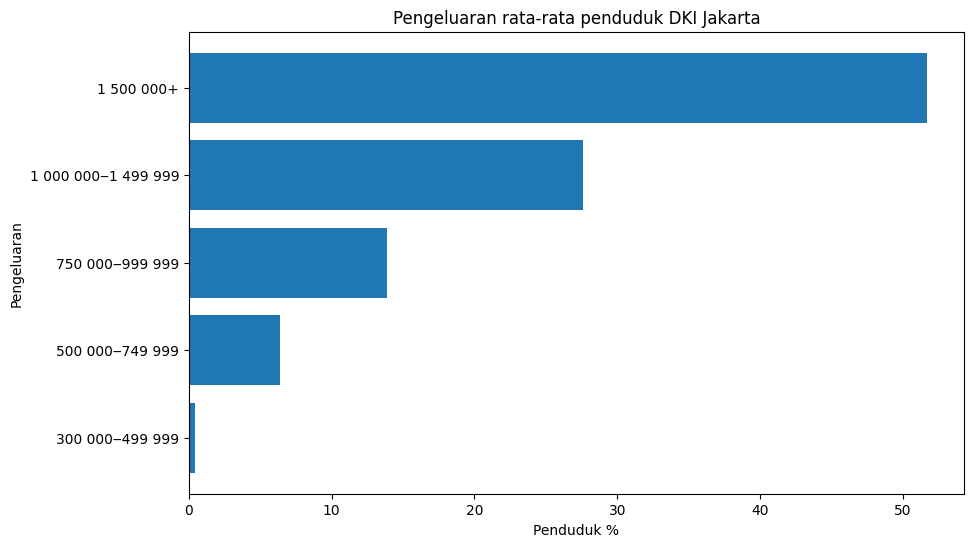

In [92]:
# Pengeluaran rata-rata penduduk DKI Jakarta

import matplotlib.pyplot as plt
import pandas as pd

dataframe = pd.concat([datacontent], axis=1)
dataframe.columns = ["datacontent"] 

data = {
    '300 000‒499 999' : [dataframe["datacontent"].iloc[0]],
    '500 000‒749 999' : [dataframe["datacontent"].iloc[1]],
    '750 000‒999 999' : [dataframe["datacontent"].iloc[2]],
    '1 000 000‒1 499 999' : [dataframe["datacontent"].iloc[3]],
    '1 500 000+' : [dataframe["datacontent"].iloc[4]]
}

Dki_jakarta = pd.DataFrame(data)

plt.figure(figsize = (10, 6))
plt.barh(Dki_jakarta.columns, Dki_jakarta.values[0])
plt.xlabel('Penduduk %')
plt.ylabel('Pengeluaran')
plt.title('Pengeluaran rata-rata penduduk DKI Jakarta')


Text(0.5, 1.0, 'Persentase penduduk yang memiliki jaminan kesehatan DKI Jakarta')

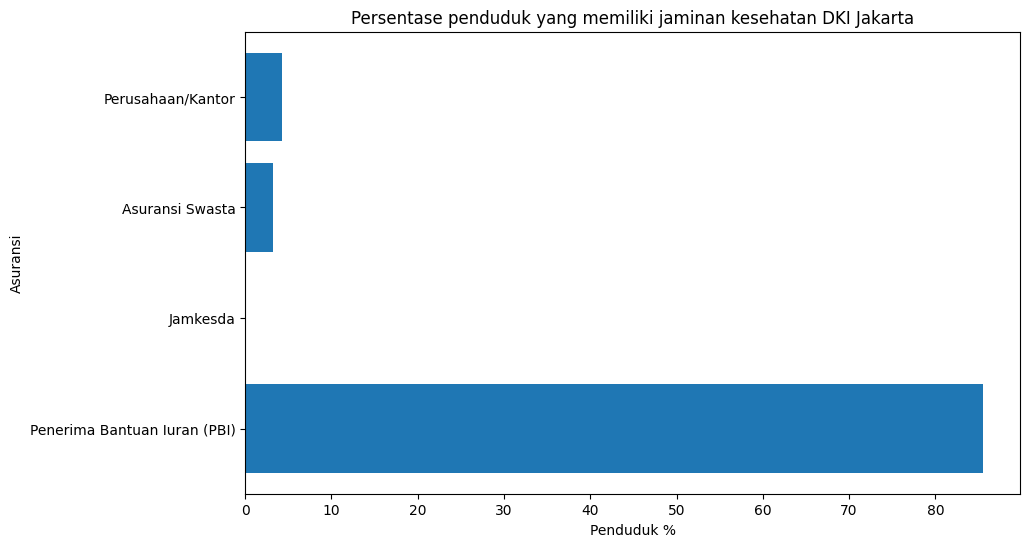

In [76]:
# Persentase Penduduk yang Memiliki Jaminan Kesehatan

import matplotlib.pyplot as plt
import pandas as pd

dataframe = pd.concat([datacontent], axis=1)
dataframe.columns = ["datacontent"] 

data = {
    'Penerima Bantuan Iuran (PBI)' : [dataframe["datacontent"].iloc[0]],
    'Jamkesda' : [dataframe["datacontent"].iloc[1]],
    'Asuransi Swasta' : [dataframe["datacontent"].iloc[2]],
    'Perusahaan/Kantor' : [dataframe["datacontent"].iloc[3]]
}

Dki_jakarta = pd.DataFrame(data)

plt.figure(figsize = (10, 6))
plt.barh(Dki_jakarta.columns, Dki_jakarta.values[0])
plt.xlabel('Penduduk %')
plt.ylabel('Asuransi')
plt.title('Persentase penduduk yang memiliki jaminan kesehatan DKI Jakarta')

Text(0.5, 1.0, 'Data kelahiran, kematian, perkawinan, perceraian, pengesahan dan pengakuan anak DKI Jakarta')

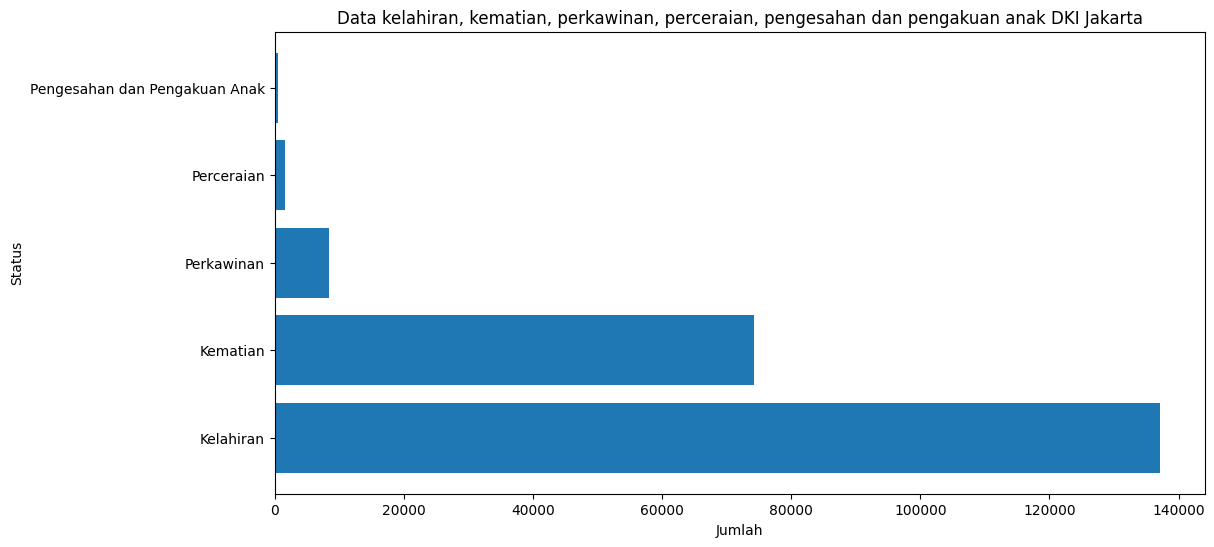

In [102]:
# Data kelahiran, kematian, perkawinan, perceraian, pengesahan dan pengakuan anak DKI Jakarta

import matplotlib.pyplot as plt
import pandas as pd

dataframe = pd.concat([datacontent], axis=1)
dataframe.columns = ["datacontent"] 

data = {
    'Kelahiran' : [dataframe["datacontent"].iloc[0]],
    'Kematian' : [dataframe["datacontent"].iloc[1]],
    'Perkawinan' : [dataframe["datacontent"].iloc[2]],
    'Perceraian' : [dataframe["datacontent"].iloc[3]],
    'Pengesahan dan Pengakuan Anak' : [dataframe["datacontent"].iloc[4]],
}

Dki_jakarta = pd.DataFrame(data)

plt.figure(figsize = (12, 6))
plt.barh(Dki_jakarta.columns, Dki_jakarta.values[0])
plt.xlabel('Jumlah')
plt.ylabel('Status')
plt.title('Data kelahiran, kematian, perkawinan, perceraian, pengesahan dan pengakuan anak DKI Jakarta')